# Hierarchical Clustering

Hierarchical Clustering is an unsupervised machine learning algorithm that groups similar observations into clusters by building a hierarchy of clusters.

It does not require the number of clusters to be specified before constructing the hierarchy. The relationships between observations are represented using a tree-like structure called a **dendrogram**.

There are two main approaches:

- **Agglomerative:** A bottom-up approach that progressively merges smaller clusters.
- **Divisive:** A top-down approach that progressively splits larger clusters.

This project focuses on Agglomerative Hierarchical Clustering.

## How It Works

1. Each observation initially forms its own cluster.
2. Distances between clusters are calculated.
3. The two closest clusters are merged.
4. Cluster distances are recalculated using a linkage method.
5. The process continues until a stopping condition is reached.
6. A dendrogram can be used to determine the final number of clusters.

## Key Concepts

- **Distance Metrics:** Measure dissimilarity between observations, such as Euclidean and Manhattan distance.
- **Linkage Methods:** Determine how distances between clusters are calculated.
- **Dendrogram:** Visualizes the hierarchy and merging process.
- **Agglomerative Clustering:** Progressively merges clusters.
- **Divisive Clustering:** Progressively splits clusters.

### Common Linkage Methods

- **Single:** Minimum distance between observations in two clusters.
- **Complete:** Maximum distance between observations in two clusters.
- **Average:** Average pairwise distance between two clusters.
- **Ward:** Minimizes the increase in within-cluster variance when merging clusters.

## Mathematical Formulations

**1. Euclidean Distance**
$$
d(A,B)=\sqrt{\sum_{i=1}^{n}(A_i-B_i)^2}
$$
**2. Manhattan Distance**
$$
d(A,B)=\sum_{i=1}^{n}|A_i-B_i|
$$
**3. Single Linkage**
$$
D(A,B)=\min_{a\in A,b\in B}d(a,b)
$$
**4. Complete Linkage**
$$
D(A,B)=\max_{a\in A,b\in B}d(a,b)
$$
**5. Average Linkage**

$$
D(A,B)=\frac{1}{|A||B|}
\sum_{a\in A}\sum_{b\in B}d(a,b)
$$
**6. Ward Linkage**
$$
\Delta(A,B)=
\frac{|A||B|}{|A|+|B|}
\|\mu_A-\mu_B\|^2
$$
## Assumptions and Considerations

- Feature scaling is important because clustering relies on distance calculations.
- The choice of distance metric and linkage method affects cluster formation.
- Outliers can influence clustering results.
- Hierarchical clustering can be computationally expensive for large datasets.
- Agglomerative merging is irreversible.

## Advantages

- Does not require specifying the number of clusters initially.
- Dendrograms provide interpretable visualizations.
- Supports different distance metrics and linkage methods.
- Can reveal nested relationships within data.

## Limitations

- Computationally expensive for large datasets.
- Sensitive to distance and linkage choices.
- Early merging decisions cannot be reversed.
- Outliers can affect cluster formation.

## Objectives

- Understand hierarchical clustering.
- Explore different linkage methods.
- Visualize cluster relationships using dendrograms.
- Determine an appropriate number of clusters.
- Train and evaluate an Agglomerative Clustering model.

In [5]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import (silhouette_score,davies_bouldin_score,calinski_harabasz_score)
import warnings
warnings.filterwarnings('ignore')

In [6]:
# load dataset
mall_df = pd.read_csv("../Datasets/Mall_Customers.csv")

print(mall_df.shape)
mall_df.head()

(200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [7]:
mall_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [8]:
mall_df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [9]:
mall_df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [10]:
mall_df.duplicated().sum()

np.int64(0)

In [11]:
# Preprocessing
X = mall_df[['Annual Income (k$)', 'Spending Score (1-100)']].copy()

X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [12]:
# scaling
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled,columns=X.columns,index=X.index)

X_scaled.head()

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


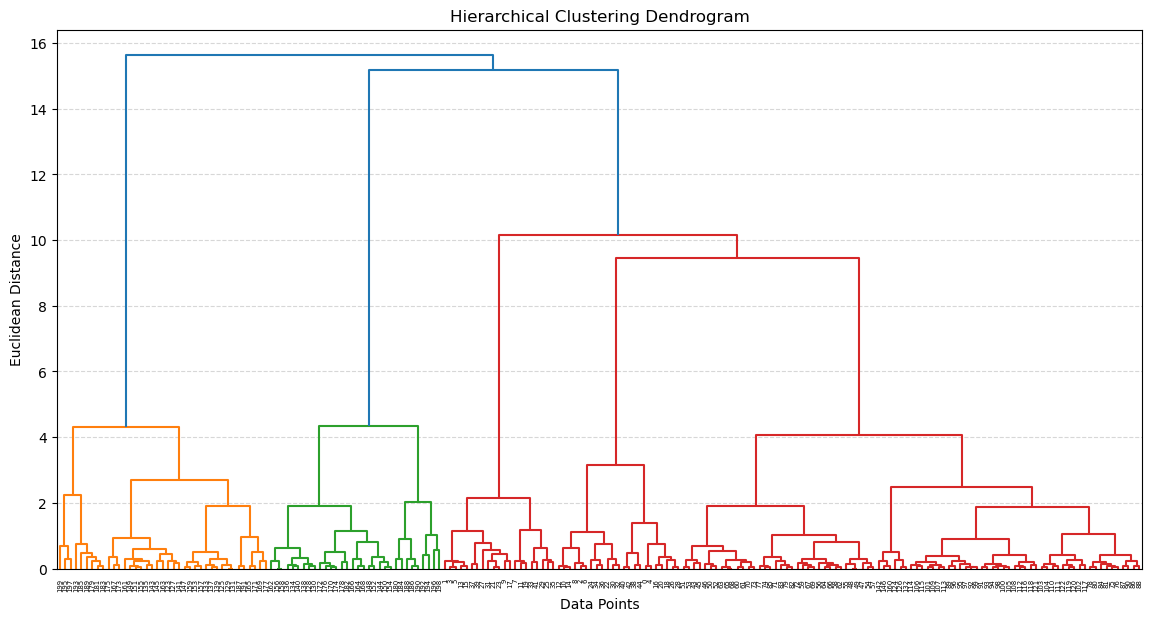

In [13]:
# Modelling
# linkage matrix
linked = linkage(X_scaled, method='ward')
plt.figure(figsize=(14, 7)) # dendogram

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

In [14]:
# Modelling
hc = AgglomerativeClustering(n_clusters=5,metric='euclidean',linkage='ward')

clusters = hc.fit_predict(X_scaled)

mall_df['Cluster'] = clusters

mall_df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,3
2,3,Female,20,16,6,4
3,4,Female,23,16,77,3
4,5,Female,31,17,40,4


In [15]:
# cluster distribution
mall_df['Cluster'].value_counts().sort_index()

Cluster
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64

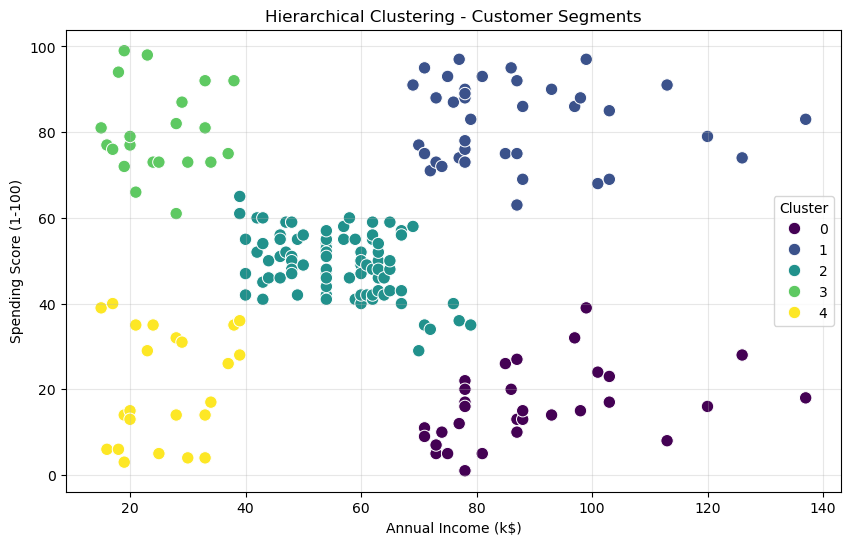

In [16]:
# cluster visualization
plt.figure(figsize=(10, 6))

sns.scatterplot(data=mall_df,x='Annual Income (k$)',y='Spending Score (1-100)',hue='Cluster',palette='viridis',s=80)

plt.title('Hierarchical Clustering - Customer Segments')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.grid(alpha=0.3)

plt.show()

In [17]:
# Evaluation
silhouette = silhouette_score(X_scaled, clusters)
davies_bouldin = davies_bouldin_score(X_scaled, clusters)
calinski_harabasz = calinski_harabasz_score(X_scaled, clusters)

print("Silhouette Score:", silhouette)
print("Davies-Bouldin Index:", davies_bouldin)
print("Calinski-Harabasz Score:", calinski_harabasz)

Silhouette Score: 0.5538089226688662
Davies-Bouldin Index: 0.5778621190740154
Calinski-Harabasz Score: 244.41032586596822


In [18]:
results = []

for k in range(2, 11):
    hc = AgglomerativeClustering(n_clusters=k,metric='euclidean',linkage='ward')

    labels = hc.fit_predict(X_scaled)

    results.append({
        'Clusters': k,
        'Silhouette Score': silhouette_score(X_scaled, labels),
        'Davies-Bouldin Index': davies_bouldin_score(X_scaled, labels),
        'Calinski-Harabasz Score': calinski_harabasz_score(X_scaled, labels)
    })

hc_results = pd.DataFrame(results)

hc_results

,Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,2,0.384234,0.854356,86.961556
1,3,0.461048,0.707287,143.779562
2,4,0.492551,0.670718,169.679831
3,5,0.553809,0.577862,244.410326
4,6,0.538676,0.644868,233.308806
5,7,0.519795,0.713283,237.258506
6,8,0.430862,0.777741,250.588294
7,9,0.437690,0.776487,252.929359
8,10,0.433901,0.766997,252.517220


## synthetic dataset

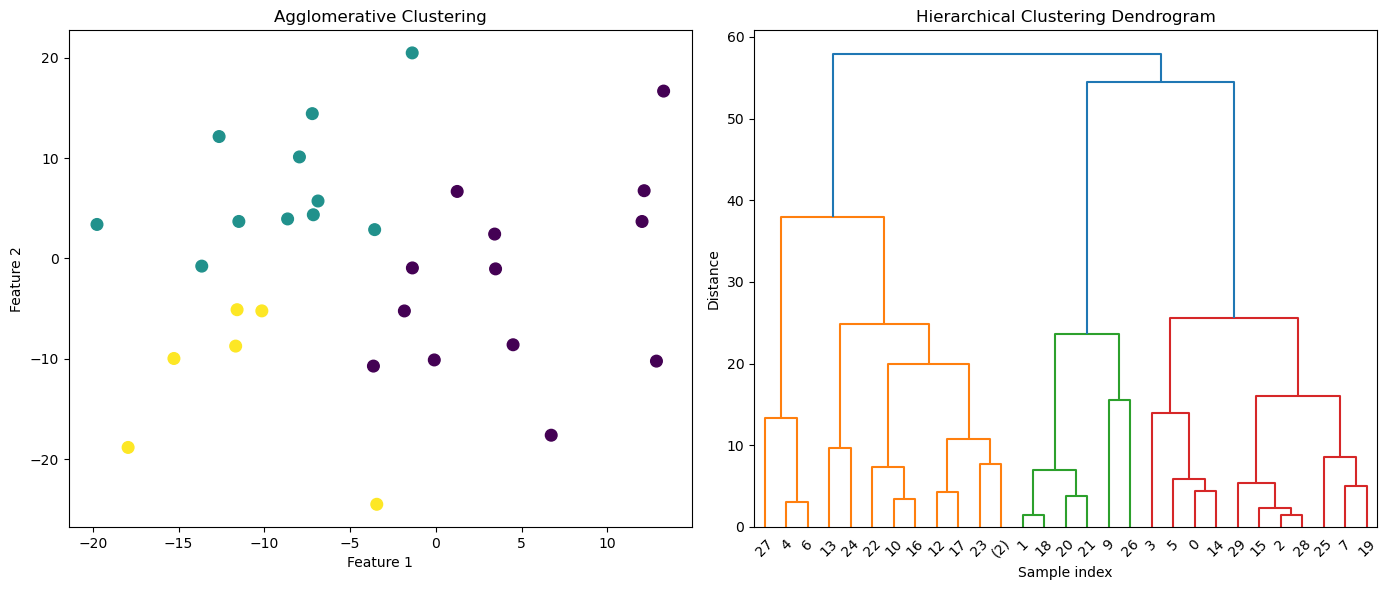

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram
from sklearn.datasets import make_blobs

X, _ = make_blobs(n_samples=30, centers=3, cluster_std=10, random_state=42)

clustering = AgglomerativeClustering(n_clusters=3)
labels = clustering.fit_predict(X)

agg = AgglomerativeClustering(distance_threshold=0,n_clusters=None,compute_distances=True)
agg.fit(X)


def plot_dendrogram(model, **kwargs):
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)

    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]).astype(float)
    dendrogram(linkage_matrix, **kwargs)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=70)
ax1.set_title("Agglomerative Clustering")
ax1.set_xlabel("Feature 1")
ax1.set_ylabel("Feature 2")

plt.sca(ax2)
plot_dendrogram(agg, truncate_mode='level', p=5)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Sample index")
plt.ylabel("Distance")

plt.tight_layout()
plt.show()

In [ ]:
# Divisive 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from scipy.cluster.hierarchy import dendrogram, linkage

X, _ = make_blobs(n_samples=30, centers=5, cluster_std=10, random_state=42)


def divisive_clustering(data, max_clusters=3):
    clusters = [data]
    while len(clusters) < max_clusters:
        cluster_to_split = max(clusters, key=lambda x: len(x))
        clusters.remove(cluster_to_split)

        kmeans = KMeans(n_clusters=2, random_state=42).fit(cluster_to_split)
        cluster1 = cluster_to_split[kmeans.labels_ == 0]
        cluster2 = cluster_to_split[kmeans.labels_ == 1]

        clusters.extend([cluster1, cluster2])
    return clusters


clusters = divisive_clustering(X, max_clusters=3)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
colors = ['r', 'g', 'b', 'c', 'm', 'y']
for i, cluster in enumerate(clusters):
    plt.scatter(cluster[:, 0], cluster[:, 1], s=50,
                c=colors[i], label=f'Cluster {i+1}')
plt.title('Divisive Clustering Result')
plt.legend()

linked = linkage(X, method='ward')

plt.subplot(1, 2, 2)
dendrogram(linked, orientation='top',
           distance_sort='descending', show_leaf_counts=True)
plt.title('Hierarchical Clustering Dendrogram')

plt.tight_layout()
plt.show()